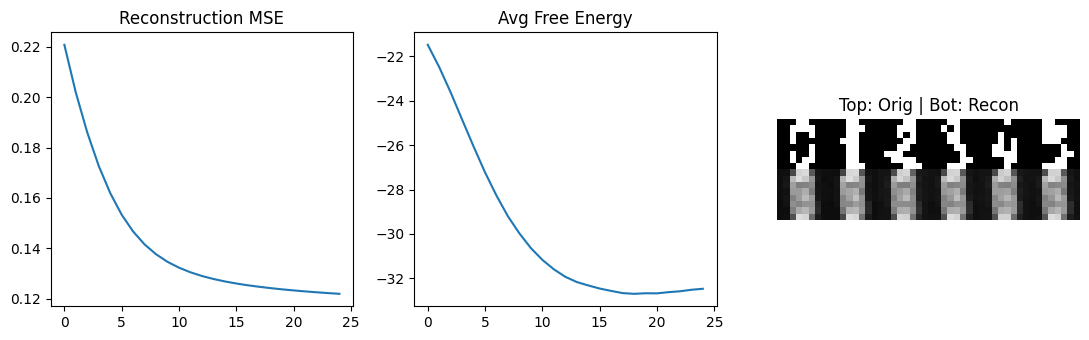

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
X = (digits.data[:400] > 8).astype(np.float32)  # 64 binary features (8x8)
n_vis, n_hid = 64, 32

rng = np.random.default_rng(42)
W = rng.normal(0, 0.1, size=(n_vis, n_hid))
a = np.zeros(n_vis)
b = np.zeros(n_hid)

def sig(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

errs, energies = [], []
for epoch in range(25):
    for x in X:
        h_prob = sig(x @ W + b)
        h_samp = (rng.random(n_hid) < h_prob).astype(float)
        v_prob = sig(h_samp @ W.T + a)
        h_prob2 = sig(v_prob @ W + b)

        W += 0.05 * (np.outer(x, h_prob) - np.outer(v_prob, h_prob2)) / len(X)
        a += 0.05 * (x - v_prob) / len(X)
        b += 0.05 * (h_prob - h_prob2) / len(X)

    h_p = sig(X @ W + b)
    rec = sig(h_p @ W.T + a)
    errs.append(np.mean((X - rec) ** 2))
    fe = -X @ a - np.sum(np.log1p(np.exp(np.clip(X @ W + b, -20, 20))), axis=1)
    energies.append(np.mean(fe))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].plot(errs); axes[0].set_title("Reconstruction MSE")
axes[1].plot(energies); axes[1].set_title("Avg Free Energy")
rec_samples = sig(sig(X[:6] @ W + b) @ W.T + a)
pair = np.vstack([np.hstack(X[:6].reshape(6, 8, 8)), np.hstack(rec_samples.reshape(6, 8, 8))])
axes[2].imshow(pair, cmap="gray"); axes[2].set_title("Top: Orig | Bot: Recon"); axes[2].axis("off")
plt.tight_layout(); plt.show()